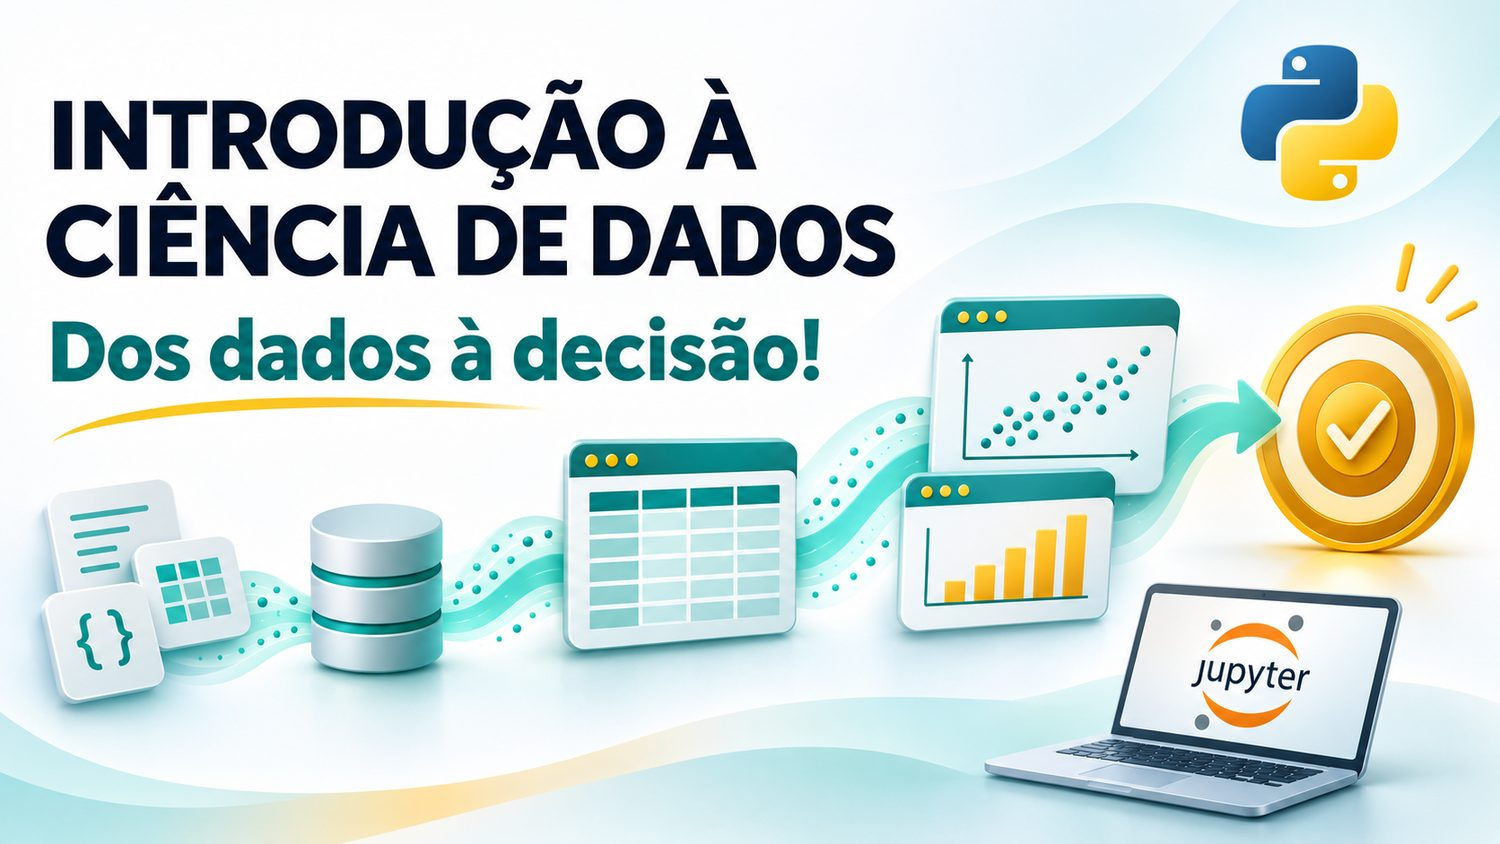

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_8_comunicar_e_usar_com_responsabilidade/02_Graficos_para_Explicar.ipynb)

# Capítulo 2 – Gráficos para explicar

No módulo 3 usámos gráficos para **explorar**: muitos, rápidos, feitos para quem os desenha. Um gráfico para **explicar** é outra coisa: um só, trabalhado, feito para quem o vai ler em dez segundos. Este capítulo mostra como passar de um ao outro, e como reconhecer um gráfico que engana.

> **Objetivos:** distinguir gráficos de exploração de gráficos de explicação; decidir a mensagem antes do gráfico; escolher o tipo de gráfico pela mensagem; retirar o que não informa; dirigir o olhar com cor e anotações; escrever títulos que são conclusões; reconhecer eixos cortados, escalas duplas e janelas escolhidas a dedo; tornar um gráfico legível para todos.

**Pré-requisitos:** capítulo 1, e o capítulo 4 do módulo 3. A sintaxe do Matplotlib está em [Visualização de dados](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_1_introducao/24_Visualizacao_Dados.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_formandos(n=6000, semente=97):
    """Gera formandos de um centro de formação profissional fictício (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    zona = rng.choice(["urbana", "rural"], n, p=[0.78, 0.22])
    rural = zona == "rural"
    idade = rng.normal(34, 10, n).clip(18, 62).round()
    escolaridade = rng.choice(["básico", "secundário", "superior"], n, p=[0.3, 0.5, 0.2])
    empregado = rng.random(n) < 0.45
    distancia = np.where(rural, rng.gamma(4.0, 6.0, n), rng.gamma(2.0, 2.5, n)).clip(0.5, 70).round(1)
    computador = rng.random(n) < np.where(rural, 0.62, 0.84)
    nota_inicial = (rng.normal(58, 15, n) + 6 * (escolaridade == "superior") - 5 * (escolaridade == "básico")).clip(5, 100).round()
    transporte_irregular = rural & (rng.random(n) < 0.30)                     # não fica registado em lado nenhum
    faltas = rng.poisson(np.clip(1.0 + 0.9 * empregado + 0.035 * distancia - 0.012 * (nota_inicial - 58) + 0.6 * ~computador, 0.15, None))
    z = (-2.95 + 0.42 * faltas + 0.55 * empregado - 0.022 * (nota_inicial - 58) + 0.55 * ~computador + 0.012 * distancia + 1.7 * transporte_irregular)
    desistiu = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"idade": idade, "zona": zona, "escolaridade": escolaridade, "empregado": empregado, "distancia_km": distancia,
                         "tem_computador": computador, "nota_inicial": nota_inicial, "faltas_primeiro_mes": faltas, "desistiu": desistiu})


formandos = gerar_formandos()
formandos.head()

,idade,zona,escolaridade,empregado,distancia_km,tem_computador,nota_inicial,faltas_primeiro_mes,desistiu
0,44.0,urbana,secundário,True,3.3,True,58.0,3,False
1,44.0,urbana,secundário,True,4.5,False,56.0,3,False
2,40.0,urbana,secundário,True,1.8,True,79.0,0,False
3,54.0,rural,básico,True,33.4,False,65.0,6,True
4,47.0,urbana,secundário,True,3.8,True,40.0,0,False


## Explorar e explicar

| | Gráfico de exploração | Gráfico de explicação |
| --- | --- | --- |
| Para quem | Para ti | Para outra pessoa |
| Pergunta | O que há aqui? | O que quero que vejas? |
| Quantos | Dezenas | Um por mensagem |
| Tempo de leitura | O que for preciso | Dez segundos |
| Título | O nome das variáveis | A conclusão |
| Acabamento | Nenhum | Tudo o que ajuda a ler, e nada mais |

O erro mais comum é pôr no relatório um gráfico de exploração. Ele contém a informação, e deixa ao leitor o trabalho de a encontrar.

## Antes e depois

A mensagem do capítulo 1: **as faltas do primeiro mês são o melhor sinal de desistência**. Eis o gráfico tal como sai de uma primeira tentativa, com as opções por omissão de há alguns anos.

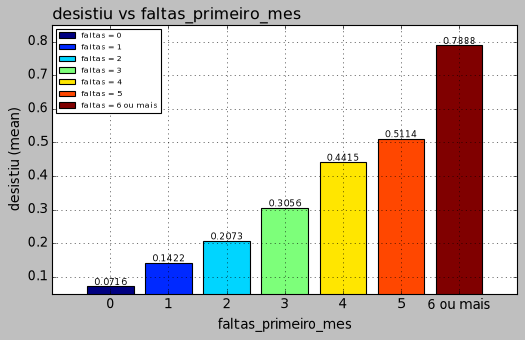

In [3]:
taxa = formandos.assign(faltas=formandos["faltas_primeiro_mes"].clip(upper=6)).groupby("faltas")["desistiu"].agg(["mean", "size"])
rotulos = [str(f) if f < 6 else "6 ou mais" for f in taxa.index]

with plt.style.context("classic"):
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    cores_arco_iris = plt.cm.jet(np.linspace(0, 1, len(taxa)))
    for i, (r, v) in enumerate(zip(rotulos, taxa["mean"])):
        ax.bar(i, v, color=cores_arco_iris[i], label=f"faltas = {r}", edgecolor="black")
        ax.text(i, v + 0.004, f"{v:.4f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(taxa)), rotulos)
    ax.set_ylim(0.05, 0.85)
    ax.grid(True)
    ax.set_xlabel("faltas_primeiro_mes")
    ax.set_ylabel("desistiu (mean)")
    ax.set_title("desistiu vs faltas_primeiro_mes")
    ax.legend(fontsize=7, loc="upper left")
    plt.show()

Não tem nenhum erro de cálculo, e quase tudo nele atrapalha.

| Problema | Porque atrapalha |
| --- | --- |
| Título com nomes de colunas | Diz o que foi desenhado, e não o que se conclui |
| Sete cores | A cor não codifica nada: repete o eixo horizontal |
| Legenda | Obriga a ir e voltar; a informação já está no eixo |
| Quatro casas decimais | Precisão que não existe e que ninguém lê |
| Grelha, moldura, contornos pretos | Tinta que não é dados |
| Eixo vertical a começar em 0,05 | Exagera as diferenças entre barras |
| Proporções em vez de percentagens | Obriga a converter de cabeça |
| Nomes técnicos nos eixos | `desistiu (mean)` não é linguagem de leitor |

O mesmo gráfico, refeito para explicar:

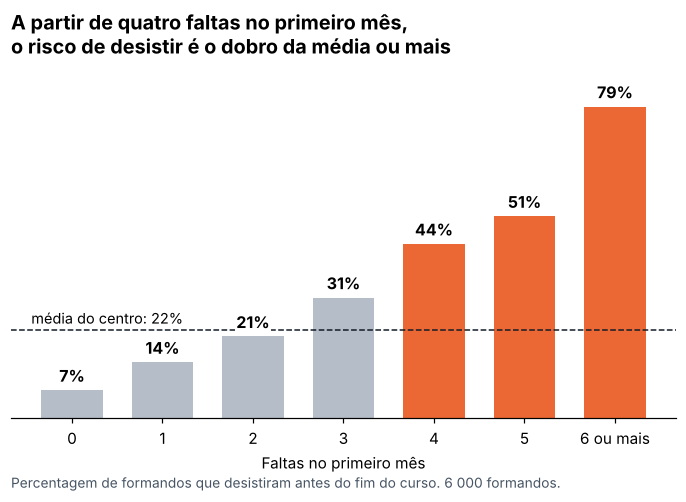

In [4]:
fig, ax = plt.subplots(figsize=(7.8, 4.2))
destaque = [LARANJA if f >= 4 else CINZA for f in taxa.index]
barras = ax.bar(rotulos, taxa["mean"] * 100, color=destaque, width=0.68)
ax.bar_label(barras, fmt="%.0f%%", padding=3, fontsize=10.5, fontweight="bold", zorder=5, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
media = formandos["desistiu"].mean() * 100
ax.axhline(media, color=TINTA, ls="--", lw=1, zorder=1)
ax.text(-0.45, media + 1.5, f"média do centro: {media:.0f}%", fontsize=9.5)
ax.set_ylim(0, 90)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.grid(False)
ax.set_xlabel("Faltas no primeiro mês")
ax.set_title("A partir de quatro faltas no primeiro mês,\no risco de desistir é o dobro da média ou mais", loc="left", fontsize=13)
fig.text(0.125, -0.04, f"Percentagem de formandos que desistiram antes do fim do curso. {len(formandos):,} formandos.".replace(",", " "), fontsize=9, color="#465463")
plt.show()

O que mudou:

1. **O título é a conclusão.** Quem só ler o título fica com a mensagem.
2. **Duas cores.** O cinzento é o contexto; a cor de destaque marca aquilo de que o título fala.
3. **Os valores estão nas barras**, e por isso o eixo vertical saiu. Com poucos valores, é mais rápido ler o número do que estimá-lo pela grelha.
4. **Uma linha de referência** (a média) dá o termo de comparação.
5. **O eixo começa em zero**: a altura das barras é proporcional aos valores.
6. **A nota de rodapé** diz o que foi medido e em quantos casos.

Nenhuma destas alterações acrescentou informação. Todas reduziram o trabalho de quem lê.

## Primeiro a mensagem, depois o gráfico

A ordem certa é escrever a frase e só depois escolher o gráfico que a mostra. Se não consegues escrever a frase, ainda não sabes o que queres mostrar, e o gráfico é de exploração.

| A mensagem é sobre | Gráfico | Cuidado |
| --- | --- | --- |
| **Comparar** grupos | Barras (horizontais, se os nomes forem longos) | Ordenar pelo valor; começar em zero |
| **Evolução** no tempo | Linha | Poucas séries; nomear as linhas diretamente |
| **Relação** entre duas quantidades | Dispersão | Transparência com muitos pontos; linha de tendência só se fizer sentido |
| **Distribuição** | Histograma, caixa de bigodes | Dizer o que é a caixa; poucas distribuições lado a lado |
| **Parte de um todo** | Uma barra empilhada, grelha de 100 | Poucas partes; evitar circulares com mais de três fatias |
| **Um número** | O número, grande, com contexto | Não fazer um gráfico de uma barra |
| **Valores exatos** de poucos itens | Uma tabela | Alinhar os números à direita; arredondar |

A última linha lembra que **nem tudo precisa de um gráfico**. Para seis números que o leitor vai querer consultar, uma tabela pequena é melhor.

## Dirigir o olhar

O olho vai primeiro para o que é diferente: uma cor entre cinzentos, uma linha mais grossa, um texto junto a um ponto. Um gráfico de explicação usa isso de propósito.

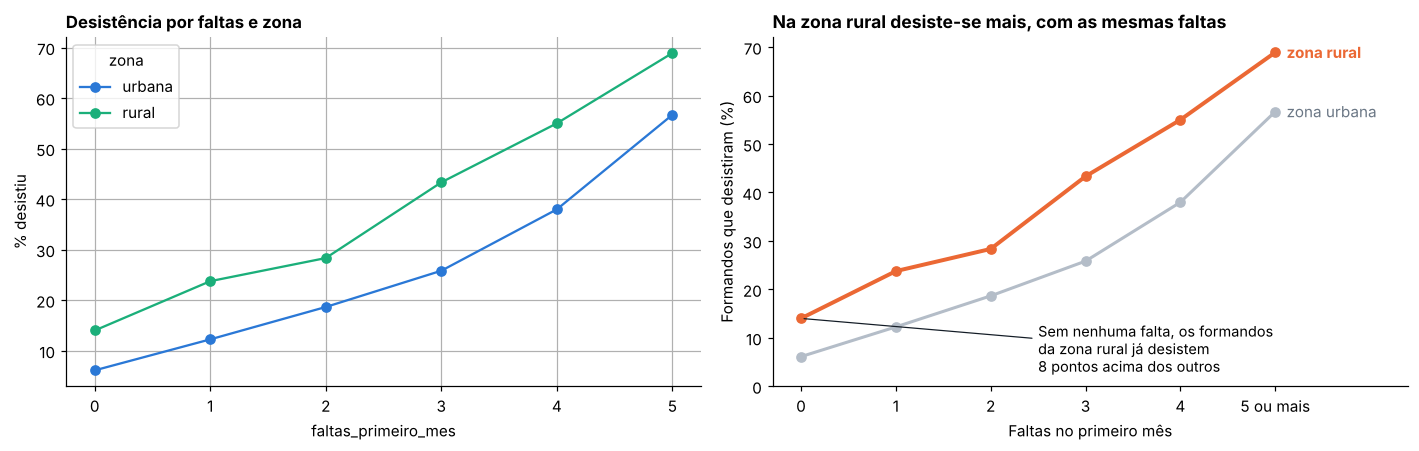

In [5]:
por_zona = formandos.groupby(["zona", formandos["faltas_primeiro_mes"].clip(upper=5)])["desistiu"].mean().unstack(0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for zona, cor in [("urbana", AZUL), ("rural", VERDE)]:
    ax1.plot(por_zona.index, por_zona[zona], "o-", color=cor, label=zona)
ax1.legend(title="zona")
ax1.grid(True)
ax1.set_xlabel("faltas_primeiro_mes")
ax1.set_ylabel("% desistiu")
ax1.set_title("Desistência por faltas e zona", fontsize=11)

ax2.plot(por_zona.index, por_zona["urbana"], "o-", color=CINZA, lw=2)
ax2.plot(por_zona.index, por_zona["rural"], "o-", color=LARANJA, lw=2.6)
ax2.text(5.12, por_zona.loc[5, "rural"], "zona rural", color=LARANJA, fontweight="bold", va="center")
ax2.text(5.12, por_zona.loc[5, "urbana"], "zona urbana", color="#6b7785", va="center")
diferenca = por_zona.loc[0, "rural"] - por_zona.loc[0, "urbana"]
ax2.annotate(f"Sem nenhuma falta, os formandos\nda zona rural já desistem\n{diferenca:.0f} pontos acima dos outros", (0, por_zona.loc[0, "rural"]), xytext=(2.5, 3), fontsize=9.5, arrowprops={"arrowstyle": "-", "color": TINTA, "lw": 0.8})
ax2.set_xlim(-0.3, 6.4)
ax2.set_ylim(0, None)
ax2.set_xticks(range(6), ["0", "1", "2", "3", "4", "5 ou mais"])
ax2.set_xlabel("Faltas no primeiro mês")
ax2.set_ylabel("Formandos que desistiram (%)")
ax2.grid(False)
ax2.set_title("Na zona rural desiste-se mais, com as mesmas faltas", loc="left", fontsize=11.5)
plt.tight_layout()
plt.show()

Os dois gráficos têm os mesmos dados. À esquerda, o leitor tem de ler a legenda, comparar as linhas e tirar a conclusão. À direita:

- **os nomes estão junto às linhas**, sem legenda;
- **uma linha está destacada**, a outra é contexto;
- **uma anotação** aponta para o sítio onde a mensagem se vê e diz o que lá está;
- **o título** diz a conclusão.

A anotação é a ferramenta mais subestimada. Uma frase curta em cima do gráfico poupa ao leitor a parte mais difícil: saber para onde olhar.

## Retirar o que não informa

Cada elemento de um gráfico ou transmite dados ou gasta atenção. Uma lista para percorrer no fim:

| Elemento | Manter se… | Senão |
| --- | --- | --- |
| Grelha | O leitor precisa de ler valores intermédios | Retirar, ou deixar muito ténue |
| Moldura | Nunca é precisa em cima e à direita | Retirar |
| Legenda | Há muitas séries | Nomear diretamente |
| Eixo com números | Os valores não estão escritos nos elementos | Retirar |
| Casas decimais | Mudam a conclusão | Arredondar |
| Cor | Codifica uma variável ou destaca | Cinzento |
| Efeitos (3D, sombras, gradientes) | Nunca | Retirar |
| Rótulos em todos os pontos | São poucos | Só nos que interessam |

A configuração que usamos em todo o tutorial já aplica várias destas regras por omissão (sem moldura em cima e à direita, grelha discreta). Vale a pena fazer o mesmo no início dos teus projetos, com `plt.rcParams`.

## Gráficos que enganam

Um gráfico pode ter todos os números certos e deixar uma impressão errada. Quase sempre sem má intenção: são opções por omissão do software ou hábitos. Os três casos mais frequentes.

### 1. Barras com o eixo cortado

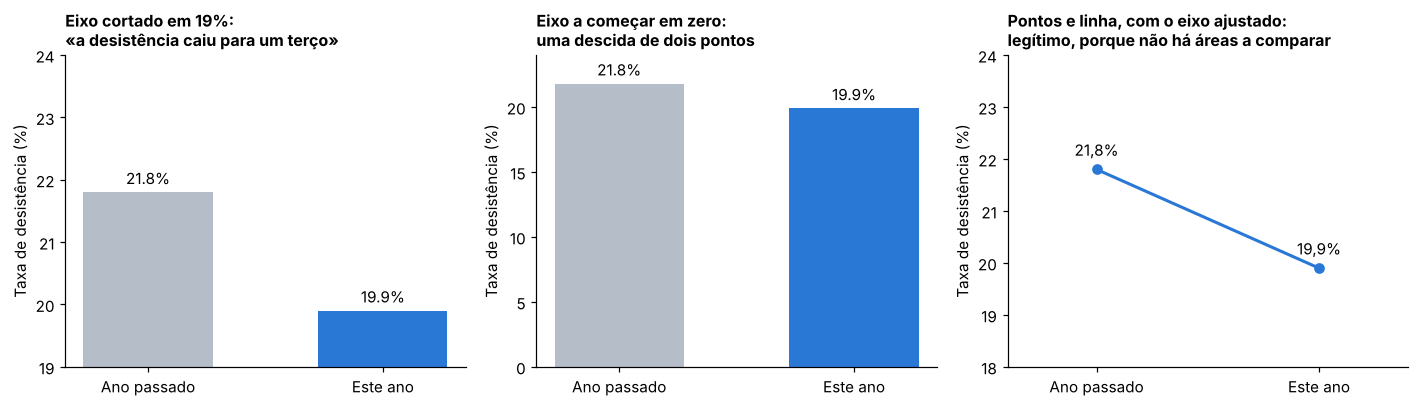

In [6]:
antes, depois = 21.8, 19.9                                   # taxa de desistência em dois anos, em %
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (minimo, titulo) in zip(eixos[:2], [(19, "Eixo cortado em 19%:\n«a desistência caiu para um terço»"), (0, "Eixo a começar em zero:\numa descida de dois pontos")]):
    barras = ax.bar(["Ano passado", "Este ano"], [antes, depois], color=[CINZA, AZUL], width=0.55)
    ax.bar_label(barras, fmt="%.1f%%", padding=3)
    ax.set_ylim(minimo, 24)
    ax.set_ylabel("Taxa de desistência (%)")
    ax.set_title(titulo, fontsize=10.5)
eixos[2].plot(["Ano passado", "Este ano"], [antes, depois], "o-", color=AZUL, lw=2)
for x, v in zip([0, 1], [antes, depois]):
    eixos[2].annotate(f"{v:.1f}%".replace(".", ","), (x, v), textcoords="offset points", xytext=(0, 9), ha="center")
eixos[2].set_ylim(18, 24)
eixos[2].set_xlim(-0.4, 1.4)
eixos[2].set_ylabel("Taxa de desistência (%)")
eixos[2].set_title("Pontos e linha, com o eixo ajustado:\nlegítimo, porque não há áreas a comparar", fontsize=10.5)
plt.tight_layout()
plt.show()

Numa barra, o que se lê é o **comprimento**. Se o eixo não começa em zero, uma barra com o triplo do comprimento não representa o triplo do valor. À esquerda, a descida de 21,8% para 19,9% parece uma queda para um terço.

A regra: **barras começam em zero**. Se a diferença que interessa é pequena e precisa de ser ampliada, usam-se pontos ou linhas, que codificam **posição** e não comprimento; aí é aceitável ajustar o eixo, desde que esteja bem assinalado.

### 2. Dois eixos verticais

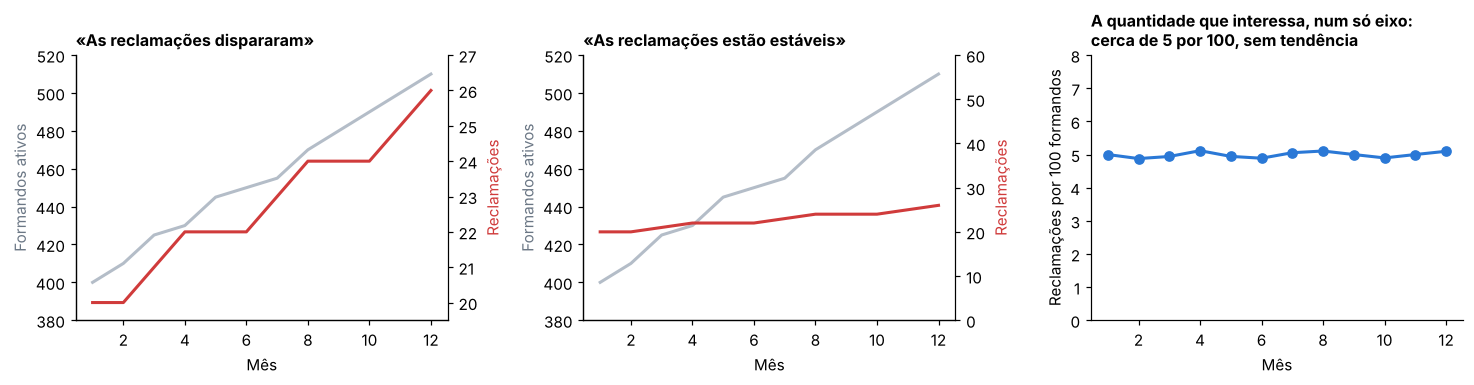

In [7]:
meses = np.arange(1, 13)
formandos_ativos = np.array([400, 410, 425, 430, 445, 450, 455, 470, 480, 490, 500, 510])
reclamacoes = np.array([20, 20, 21, 22, 22, 22, 23, 24, 24, 24, 25, 26])

fig, eixos = plt.subplots(1, 3, figsize=(13.5, 3.6))
for ax, limites, titulo in [(eixos[0], (19.5, 27), "«As reclamações dispararam»"), (eixos[1], (0, 60), "«As reclamações estão estáveis»")]:
    ax.plot(meses, formandos_ativos, color=CINZA, lw=2)
    ax.set_ylim(380, 520)
    ax.set_ylabel("Formandos ativos", color="#6b7785")
    outro = ax.twinx()
    outro.plot(meses, reclamacoes, color=MAU, lw=2)
    outro.set_ylim(*limites)
    outro.set_ylabel("Reclamações", color=MAU)
    outro.spines["right"].set_visible(True)
    outro.grid(False)
    ax.set_xlabel("Mês")
    ax.set_title(titulo, fontsize=10.5)
eixos[2].plot(meses, reclamacoes / formandos_ativos * 100, "o-", color=AZUL, lw=2)
eixos[2].set_ylim(0, 8)
eixos[2].set_xlabel("Mês")
eixos[2].set_ylabel("Reclamações por 100 formandos")
eixos[2].set_title("A quantidade que interessa, num só eixo:\ncerca de 5 por 100, sem tendência", fontsize=10.5)
plt.tight_layout()
plt.show()

Os dois primeiros gráficos têm **exatamente os mesmos dados**. Só muda a escala do eixo da direita, que é arbitrária: quem desenha escolhe onde as linhas se cruzam e quão inclinadas parecem. Com dois eixos pode contar-se a história que se quiser.

A alternativa é quase sempre calcular a quantidade que realmente interessa (aqui, as reclamações **por formando**) e desenhá-la num só eixo. Se as duas séries têm mesmo de aparecer, dois gráficos pequenos, um por cima do outro, com o mesmo eixo horizontal.

### 3. A janela escolhida a dedo

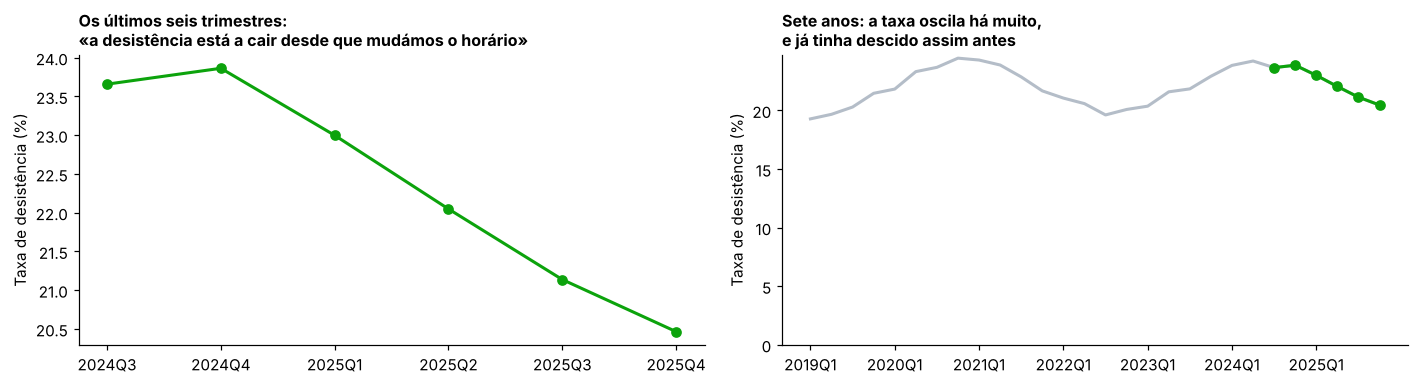

In [8]:
rng = np.random.default_rng(8)
trimestres = pd.period_range("2019Q1", periods=28, freq="Q")
serie = 22 + 2.2 * np.sin((np.arange(28) - 17.9) / 2.3) + rng.normal(0, 0.3, 28)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.6))
ax1.plot(range(6), serie[-6:], "o-", color=BOM, lw=2)
ax1.set_xticks(range(6), [str(t) for t in trimestres[-6:]])
ax1.set_ylabel("Taxa de desistência (%)")
ax1.set_title("Os últimos seis trimestres:\n«a desistência está a cair desde que mudámos o horário»", fontsize=10.5)
ax2.plot(range(28), serie, color=CINZA, lw=2)
ax2.plot(range(22, 28), serie[-6:], "o-", color=BOM, lw=2)
ax2.set_xticks(range(0, 28, 4), [str(t) for t in trimestres[::4]])
ax2.set_ylim(0, None)
ax2.set_ylabel("Taxa de desistência (%)")
ax2.set_title("Sete anos: a taxa oscila há muito,\ne já tinha descido assim antes", fontsize=10.5)
plt.tight_layout()
plt.show()

O gráfico da esquerda não mente em nenhum ponto. Mostra só o troço em que a história fica bem contada. Com a série inteira, a «descida» é mais uma oscilação entre outras (módulo 3, capítulo 6).

Quem escolhe o início de uma série escolhe a conclusão. A defesa é mostrar o período **todo**, ou dizer porque se escolheu aquele.

### Uma lista para desconfiar

| Sinal | Pergunta a fazer |
| --- | --- |
| Barras que não começam em zero | A diferença seria visível com o eixo completo? |
| Dois eixos verticais | Quem escolheu as escalas, e porquê assim? |
| Série temporal curta | O que aconteceu antes? |
| Percentagens sem o número de casos | Percentagem de quantos? |
| «Cresceu 50%» sem ponto de partida | De 2 para 3, ou de 2 000 para 3 000? |
| Áreas, volumes e pictogramas de tamanhos diferentes | O que é proporcional ao valor: a altura ou a área? |
| Gráfico circular com muitas fatias, ou em 3D | Consigo comparar duas fatias sem ler os números? |
| Mapa colorido por totais | Não será só um mapa de onde vive mais gente? |

A lista serve para ler os gráficos dos outros e, sobretudo, para rever os próprios.

## Legível para todos

- **Cor.** Cerca de 1 em cada 12 homens e 1 em cada 200 mulheres distingue mal o vermelho do verde. Nunca usar só esse par para separar «bom» de «mau»: juntar posição, forma, um rótulo ou uma diferença de claridade.
- **Não depender só da cor.** Um gráfico deve continuar a ler-se impresso a preto e branco.
- **Tamanho do texto.** O gráfico vai ser visto num diapositivo ao fundo de uma sala, ou num telemóvel. Se os rótulos não se leem a essa distância, não existem.
- **Texto alternativo.** Quem usa um leitor de ecrã precisa de uma descrição: a mensagem do gráfico e os números principais, em duas frases.
- **Ordem e orientação.** Texto na horizontal sempre que possível; barras horizontais quando os nomes são compridos.

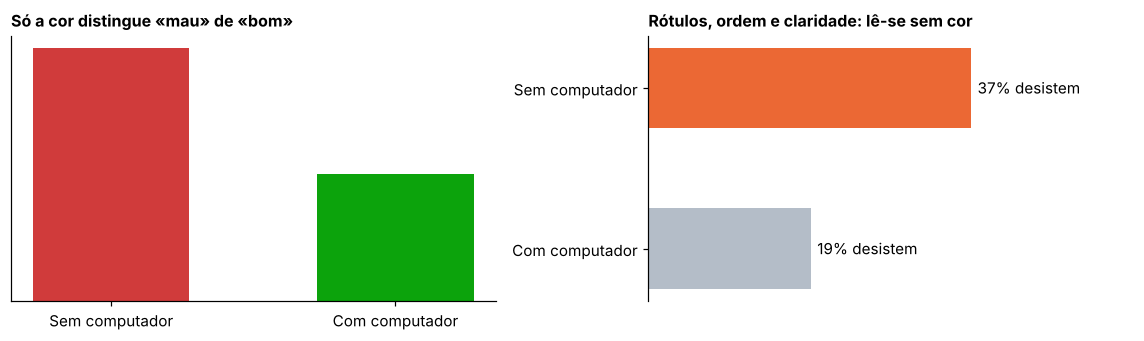

In [9]:
grupos = formandos.groupby("tem_computador")["desistiu"].mean() * 100
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.2))
ax1.bar(["Sem computador", "Com computador"], [grupos[False], grupos[True]], color=["#d03b3b", "#0ca30c"], width=0.55)
ax1.set_yticks([])
ax1.set_title("Só a cor distingue «mau» de «bom»", fontsize=10.5)
barras = ax2.barh(["Com computador", "Sem computador"], [grupos[True], grupos[False]], color=[CINZA, LARANJA], height=0.5)
ax2.bar_label(barras, fmt="%.0f%% desistem", padding=4, fontsize=10)
ax2.set_xlim(0, grupos.max() * 1.5)
ax2.set_xticks([])
ax2.spines["bottom"].set_visible(False)
ax2.grid(False)
ax2.set_title("Rótulos, ordem e claridade: lê-se sem cor", fontsize=10.5)
plt.tight_layout()
plt.show()

Um texto alternativo para o gráfico da direita: *«Gráfico de barras. Entre os formandos sem computador em casa, 37% desistem; entre os que têm, 19%.»* Diz o tipo de gráfico, a comparação e os dois números. Não descreve cores nem posições.

## Uma lista de verificação antes de enviar

1. Consigo dizer a mensagem numa frase? Está no título?
2. O tipo de gráfico corresponde à mensagem?
3. O olhar vai primeiro para o sítio certo?
4. Há algum elemento que possa sair sem se perder informação?
5. Os eixos são honestos (zero nas barras, uma só escala, período completo)?
6. As unidades, o universo e o número de casos estão escritos?
7. Lê-se a preto e branco, e em pequeno?
8. Alguém que não conhece o trabalho percebe-o em dez segundos? (Experimenta com uma pessoa.)

## Exercícios

### `Exercício 1` – Que gráfico?

Para cada mensagem, indica o tipo de gráfico (ou se basta um número ou uma tabela).

1. «A taxa de desistência subiu nos últimos três anos em todos os cursos menos um.»
2. «Um quinto dos formandos desiste.»
3. «Os formandos que moram mais longe faltam mais.»
4. «O curso de soldadura tem a maior taxa de desistência, o de contabilidade a menor.»
5. «A nota inicial dos que desistem é parecida com a dos que ficam.»

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Linhas**, uma por curso, todas a cinzento e a exceção destacada com cor e com o nome.
2. **Um número**, grande: «1 em cada 5». Ou uma grelha de 100 pessoas, se for para uma apresentação.
3. **Dispersão** da distância contra as faltas; com muitos pontos, as médias por classes de distância mostram melhor a tendência.
4. **Barras horizontais**, ordenadas da maior para a menor taxa, com os dois extremos destacados.
5. **Duas distribuições sobrepostas** ou duas caixas de bigodes lado a lado. O título diz a conclusão, porque um resultado «sem diferença» não se vê sozinho.

</details>

### `Exercício 2` – Refazer um gráfico

O código seguinte produz um gráfico de exploração da taxa de desistência por escolaridade e situação de emprego. Escreve a mensagem numa frase e refaz o gráfico para a explicar.

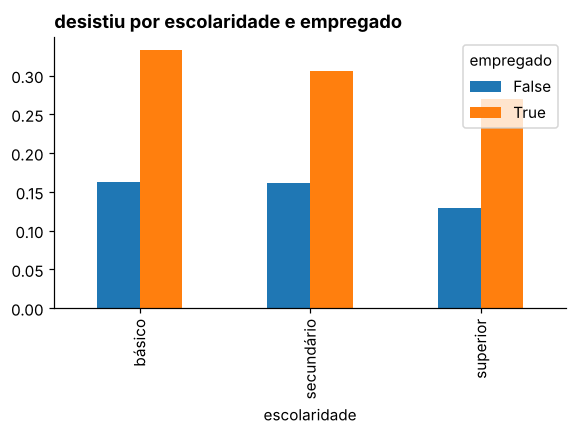

In [10]:
exploracao = formandos.groupby(["escolaridade", "empregado"])["desistiu"].mean().unstack()
exploracao.plot(kind="bar", figsize=(6, 3.2), title="desistiu por escolaridade e empregado")
plt.show()
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
tabela = (exploracao * 100).loc[["básico", "secundário", "superior"]]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
posicoes = np.arange(3)
b1 = ax.bar(posicoes - 0.2, tabela[False], 0.38, color=CINZA)
b2 = ax.bar(posicoes + 0.2, tabela[True], 0.38, color=LARANJA)
ax.bar_label(b1, fmt="%.0f%%", padding=2)
ax.bar_label(b2, fmt="%.0f%%", padding=2, fontweight="bold")
ax.text(2.2, tabela.loc["superior", True] + 6, "trabalham", color=LARANJA, fontweight="bold", ha="center")
ax.text(1.8, tabela.loc["superior", False] + 6, "não trabalham", color="#6b7785", ha="center")
ax.set_xticks(posicoes, ["Ensino básico", "Secundário", "Superior"])
ax.set_yticks([]); ax.set_ylim(0, tabela.max().max() + 14); ax.grid(False); ax.spines["left"].set_visible(False)
ax.set_title("Quem trabalha ao mesmo tempo desiste mais,\nem todos os níveis de escolaridade", loc="left")
plt.show()
```

A mensagem: «Quem trabalha ao mesmo tempo desiste mais, qualquer que seja a escolaridade.» O gráfico destaca essa comparação (a cor separa quem trabalha de quem não trabalha), nomeia as séries junto às barras e escreve os valores. A escolaridade fica como contexto: mostra que o efeito se repete nos três níveis.

</details>

### `Exercício 3` – Encontrar o engano

Um relatório mostra um gráfico de barras com o título «O novo método de ensino duplicou a taxa de conclusão». As barras têm os valores 78% e 81%, e o eixo vertical vai de 75% a 82%. Indica o que está errado e como o corrigir. Que mais gostarias de saber antes de acreditar na conclusão?

<details>
<summary><b>Ver uma solução possível</b></summary>

O eixo cortado faz a segunda barra ter o dobro da altura da primeira (6 contra 3 unidades acima de 75), quando a diferença real é de três pontos percentuais. A taxa não duplicou: subiu de 78% para 81%.

Correção: começar o eixo em zero (as barras ficarão quase iguais, que é a verdade), ou usar dois pontos com os valores escritos e um título honesto: «A taxa de conclusão subiu três pontos».

Antes de acreditar: quantos formandos há em cada grupo (com 50 em cada, três pontos são um ou dois formandos, dentro do acaso); se os dois grupos são comparáveis (os mesmos cursos, o mesmo ano, a mesma forma de selecionar); e se a taxa já oscilava deste tamanho de um ano para o outro antes do novo método.

</details>

### `Exercício 4` – Texto alternativo

Escreve o texto alternativo (duas frases, no máximo) do gráfico «depois» das faltas, no início do capítulo.

<details>
<summary><b>Ver uma solução possível</b></summary>

«Gráfico de barras da percentagem de formandos que desistem, por número de faltas no primeiro mês: sobe de 7% sem faltas para quase 80% com seis ou mais. A partir de quatro faltas, a taxa é o dobro ou mais da média do centro, que é de 22%.»

(Os valores exatos estão no gráfico. O texto diz o tipo de gráfico, a tendência, os extremos e a mensagem.)

</details>

## Verifica o que aprendeste

- [ ] Sei distinguir um gráfico de exploração de um de explicação.
- [ ] Sei escolher o tipo de gráfico a partir da mensagem.
- [ ] Sei escrever um título que é uma conclusão.
- [ ] Sei usar cor, nomes diretos e anotações para dirigir o olhar.
- [ ] Sei retirar o que não informa.
- [ ] Sei reconhecer um eixo cortado, um eixo duplo e uma janela escolhida a dedo.
- [ ] Sei tornar um gráfico legível sem depender da cor.

## Leitura recomendada

- https://matplotlib.org/stable/gallery/text_labels_and_annotations/index.html
- https://en.wikipedia.org/wiki/Misleading_graph
- https://en.wikipedia.org/wiki/Chartjunk
- https://www.w3.org/WAI/tutorials/images/complex/